# ESA cropland and LGRIP irrigated / rainfed — Morocco

Reference layers for the irrigated-area mapping work.

- **ESA cropland:** class 40 of [ESA WorldCover v200](https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v200) (2021, 10 m).
- **LGRIP30:** GFSAD Landsat rainfed and irrigated cropland (`projects/sat-io/open-datasets/GFSAD/LGRIP30`, nominal 2015, 30 m).



In [9]:
import io
import json
from pathlib import Path

import ee
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from PIL import Image

In [10]:
import json

def ee_authenticate():
    with open("waterinfor-service-account.json") as f:
        service_account_key = json.load(f)
    
    credentials = ee.ServiceAccountCredentials(
        service_account_key['client_email'],
        key_data=json.dumps(service_account_key)
    )
    ee.Initialize(credentials)
    print("GEE Initialized")

ee_authenticate()

GEE Initialized


In [11]:
ROOT = Path.cwd()


KEY_FILE = ROOT / "waterinfor-service-account.json"
BOUNDARY = ROOT / "Morocco_data" / "Morocco_Admin_Boundary" / "gadm41_MAR_0.json"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

ESA_CROP_COLOR = "#f096ff"
LGRIP_IRRIGATED = "#c2d30c"
LGRIP_RAINFED = "#379a4b"
LAND_COLOR = "#f4f1ea"
AREA_SCALE_M = 100

print(ROOT)

/Users/amanchaudhary/Desktop/SSD/Irrigated_Area_Maping_Thesis/irrigated_area_mapping_code


In [12]:
boundary = gpd.read_file(BOUNDARY)
morocco = ee.Geometry(boundary.union_all().__geo_interface__)
bounds = morocco.bounds()
coords = bounds.coordinates().getInfo()[0]
xs = [pt[0] for pt in coords]
ys = [pt[1] for pt in coords]
extent = [min(xs), max(xs), min(ys), max(ys)]
extent

[-13.1679, -0.9963, 27.670099999999977, 35.92260000000003]

## Layers

ESA WorldCover is mosaicked over Morocco and kept where the map class is cropland (40).
LGRIP is mosaicked the same way. Classes 2 and 3 are remapped to 1 and 2 so they can be painted as irrigated and rainfed.

In [13]:
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .filterBounds(morocco)
    .mosaic()
    .select("Map")
    .clip(morocco)
)
esa_cropland = worldcover.eq(40).selfMask().rename("esa_cropland")

lgrip = (
    ee.ImageCollection("projects/sat-io/open-datasets/GFSAD/LGRIP30")
    .mosaic()
    .clip(morocco)
)
lgrip = lgrip.select([lgrip.bandNames().get(0)]).rename("lgrip")
lgrip_crop = lgrip.remap([2, 3], [1, 2]).selfMask().rename("lgrip_crop")

In [14]:
def paint(base_color, overlay, palette):
    land = ee.Image.constant(1).clip(morocco).visualize(
        min=0, max=1, palette=[base_color]
    )
    painted = overlay.visualize(min=1, max=len(palette), palette=palette)
    return ee.ImageCollection([land, painted]).mosaic()


def download_png(image, region, dimensions=1400):
    url = image.getThumbURL({"region": region, "dimensions": dimensions, "format": "png"})
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    return Image.open(io.BytesIO(response.content)).convert("RGBA")


esa_img = download_png(paint(LAND_COLOR, esa_cropland, [ESA_CROP_COLOR]), bounds)
lgrip_img = download_png(
    paint(LAND_COLOR, lgrip_crop, [LGRIP_IRRIGATED, LGRIP_RAINFED]),
    bounds,
)

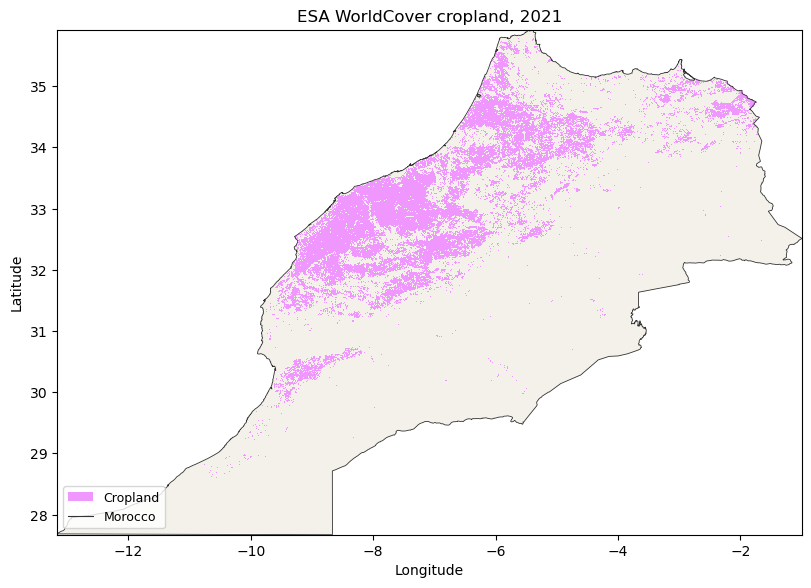

Saved /Users/amanchaudhary/Desktop/SSD/Irrigated_Area_Maping_Thesis/irrigated_area_mapping_code/outputs/morocco_esa_cropland.png


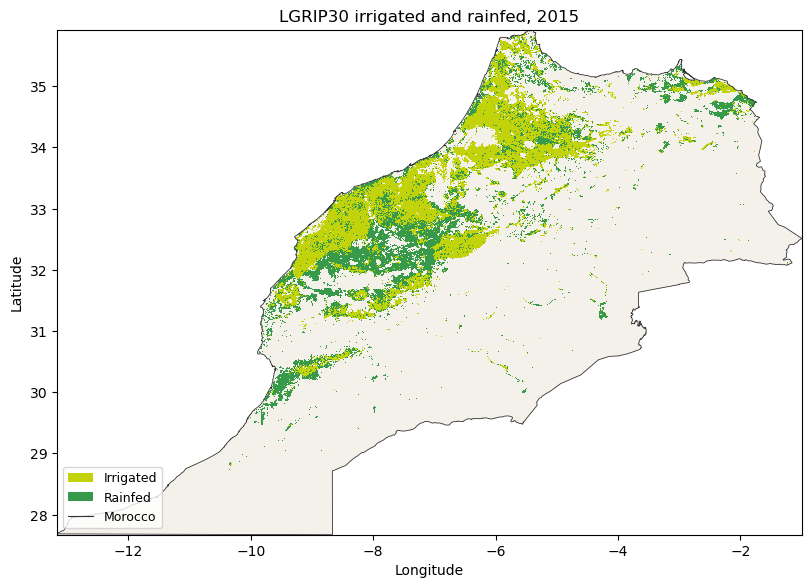

Saved /Users/amanchaudhary/Desktop/SSD/Irrigated_Area_Maping_Thesis/irrigated_area_mapping_code/outputs/morocco_lgrip_irrigated_rainfed.png


In [15]:
panels = [
    (
        esa_img,
        "ESA WorldCover cropland, 2021",
        OUT_DIR / "morocco_esa_cropland.png",
        [Patch(facecolor=ESA_CROP_COLOR, edgecolor="none", label="Cropland")],
    ),
    (
        lgrip_img,
        "LGRIP30 irrigated and rainfed, 2015",
        OUT_DIR / "morocco_lgrip_irrigated_rainfed.png",
        [
            Patch(facecolor=LGRIP_IRRIGATED, edgecolor="none", label="Irrigated"),
            Patch(facecolor=LGRIP_RAINFED, edgecolor="none", label="Rainfed"),
        ],
    ),
]
for image, title, png_path, handles in panels:
    fig, ax = plt.subplots(figsize=(8, 7.2), constrained_layout=True)
    ax.imshow(image, extent=extent, interpolation="nearest")
    boundary.boundary.plot(ax=ax, color="#333333", linewidth=0.6)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title, fontsize=12)
    handles.append(Line2D([0], [0], color="#333333", linewidth=0.8, label="Morocco"))
    ax.legend(handles=handles, loc="lower left", frameon=True, fontsize=9)
    fig.savefig(png_path, dpi=160)
    plt.show()
    print(f"Saved {png_path}")